# 🚕 Uber — Taxi Demand Forecasting
## Research Diary

**Goal:** Predict taxi demand for the **next 7 days** (672 × 15-min intervals) across **77 city areas**.  
**Target metric:** average MAE ≤ 10.0 on the held-out test set.

---
### Methods covered (mandatory part)
| # | Method | Key idea |
|---|--------|----------|
| 1 | **Naive Averages** | Global mean per area |
| 2 | **Moving Averages** | Rolling-window mean (several windows tested) |
| 3 | **Exponential Smoothing** | Best of SES / Holt / Holt-Winters chosen by AIC |
| 4 | **SARIMA** | AIC grid-search over (p,d,q) × seasonal orders |

## 0 — Install dependencies

In [7]:
!pip install statsmodels scikit-learn pandas numpy --quiet

## 1 — Upload datasets

Run this cell and upload **both** files when prompted:
- `taxi_pickups_area.csv`
- `taxi_submission_file.csv`

In [8]:
import io
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

try:
    from google.colab import files
    print('Running on Google Colab — please upload both CSV files.')
    uploaded = files.upload()

    PICKUPS_CSV    = io.BytesIO(uploaded['taxi_pickups_area.csv'])
    SUBMISSION_CSV = io.BytesIO(uploaded['taxi_submission_file.csv'])

except (ImportError, ModuleNotFoundError):
    print('Not on Colab — loading from local data/ folder.')
    PICKUPS_CSV    = 'data/taxi_pickups_area.csv'
    SUBMISSION_CSV = 'data/taxi_submission_file.csv'

print('Files ready ✓')

Running on Google Colab — please upload both CSV files.


Saving taxi_submission_file.csv to taxi_submission_file.csv
Saving taxi_pickups_area.csv to taxi_pickups_area.csv
Files ready ✓


## 2 — Load & parse data

In [9]:

df = pd.read_csv(PICKUPS_CSV)
df['Trip Start Timestamp'] = pd.to_datetime(df['Trip Start Timestamp'])
df = df.sort_values('Trip Start Timestamp').reset_index(drop=True)

submission_df = pd.read_csv(SUBMISSION_CSV)
submission_df['Trip Start Timestamp'] = pd.to_datetime(submission_df['Trip Start Timestamp'])

NUM_INTERVALS = len(submission_df)
VAL_SIZE      = NUM_INTERVALS

AREA_COLS  = [c for c in df.columns if c != 'Trip Start Timestamp']
train_data = df.iloc[:-VAL_SIZE].copy()
val_data   = df.iloc[-VAL_SIZE:].copy()

print(f'Areas              : {len(AREA_COLS)}')
print(f'Full dataset       : {df.shape[0]} rows')
print(f'Train              : {train_data.shape[0]} rows  '
      f'({train_data["Trip Start Timestamp"].min()} → {train_data["Trip Start Timestamp"].max()})')
print(f'Validation         : {val_data.shape[0]} rows  '
      f'({val_data["Trip Start Timestamp"].min()} → {val_data["Trip Start Timestamp"].max()})')
print(f'Test intervals     : {NUM_INTERVALS}')

Areas              : 78
Full dataset       : 8064 rows
Train              : 7392 rows  (2019-04-01 00:00:00 → 2019-06-16 23:45:00)
Validation         : 672 rows  (2019-06-17 00:00:00 → 2019-06-23 23:45:00)
Test intervals     : 672


## 3 — Quick EDA

Per-area mean pickups (train):
count    78.000
mean      3.972
std      14.558
min       0.010
25%       0.055
50%       0.132
75%       0.610
max      89.722
dtype: float64


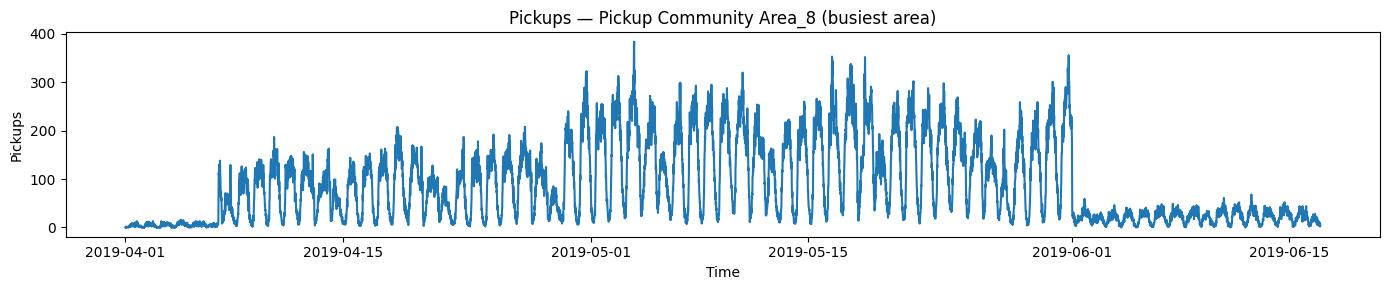

In [10]:
print('Per-area mean pickups (train):')
print(train_data[AREA_COLS].mean().describe().round(3))

try:
    import matplotlib.pyplot as plt
    busiest = train_data[AREA_COLS].mean().idxmax()
    plt.figure(figsize=(14, 3))
    plt.plot(train_data['Trip Start Timestamp'], train_data[busiest])
    plt.title(f'Pickups — {busiest} (busiest area)')
    plt.xlabel('Time')
    plt.ylabel('Pickups')
    plt.tight_layout()
    plt.show()
except Exception:
    pass

## 4 — Shared helpers

In [11]:
from sklearn.metrics import mean_absolute_error

def compute_mae(val_df, preds_df):
    """Average MAE across all area columns."""
    return float(np.mean([
        mean_absolute_error(val_df[col].values, preds_df[col].values)
        for col in AREA_COLS
    ]))

def make_submission(test_preds_df):
    """Fill the submission template with test predictions."""
    sub = submission_df.copy()
    for col in AREA_COLS:
        sub[col] = np.maximum(test_preds_df[col].values, 0)
    return sub

RESULTS = {}

---
## Method 1 — Naive Averages

**Idea:** predict the **global mean** of each area for every future interval.  
**Rationale:** simplest possible baseline — ignores all temporal structure.  
**Requirement:** compute MAE on own validation set.

In [12]:

global_means = train_data[AREA_COLS].mean()

naive_val_preds  = pd.DataFrame(
    np.tile(global_means.values, (len(val_data), 1)),
    columns=AREA_COLS
)
naive_test_preds = pd.DataFrame(
    np.tile(global_means.values, (NUM_INTERVALS, 1)),
    columns=AREA_COLS
)

naive_mae = compute_mae(val_data, naive_val_preds)
print(f'Naive Averages  Validation MAE: {naive_mae:.4f}')

RESULTS['Naive Averages'] = (naive_mae, make_submission(naive_test_preds))

Naive Averages  Validation MAE: 3.1035


---
## Method 2 — Moving Averages

**Idea:** predict each area using the last **rolling-window mean** of the training series.  
**Rationale:** more responsive than a global mean; captures recent demand level.  
**We test several window sizes** and pick the best.

In [13]:

window_results = {}

for window in [48, 96, 192, 336, 672]:
    val_preds = {}
    for area in AREA_COLS:
        rm = train_data[area].rolling(window=window).mean().iloc[-1]
        if np.isnan(rm):
            rm = train_data[area].mean()
        val_preds[area] = np.full(len(val_data), rm)

    mae = compute_mae(val_data, pd.DataFrame(val_preds))
    window_results[window] = mae
    print(f'  window={window:4d}  MAE={mae:.4f}')

best_window = min(window_results, key=window_results.get)
print(f'\nBest window: {best_window} intervals  (MAE={window_results[best_window]:.4f})')

  window=  48  MAE=0.6827
  window=  96  MAE=0.6741
  window= 192  MAE=0.6647
  window= 336  MAE=0.6454
  window= 672  MAE=0.6492

Best window: 336 intervals  (MAE=0.6454)


In [14]:

moving_val_preds  = {}
moving_test_preds = {}

for area in AREA_COLS:
    rm = train_data[area].rolling(window=best_window).mean().iloc[-1]
    if np.isnan(rm):
        rm = train_data[area].mean()
    moving_val_preds[area]  = np.full(len(val_data),    rm)
    moving_test_preds[area] = np.full(NUM_INTERVALS, rm)

moving_mae = compute_mae(val_data, pd.DataFrame(moving_val_preds))
print(f'Moving Averages  Validation MAE: {moving_mae:.4f}')

RESULTS['Moving Averages'] = (moving_mae, make_submission(pd.DataFrame(moving_test_preds)))

Moving Averages  Validation MAE: 0.6454


---
## Method 3 — Exponential Smoothing (3 algorithms)

Per the subject, **3 different exponential-smoothing algorithms** are tested per area, with weights optimised automatically. The one with the lowest **AIC** is selected:

| Algo | Trend | Seasonality | Notes |
|------|-------|-------------|-------|
| **SES** | ✗ | ✗ | Simple exponential smoothing |
| **Holt (Double ES)** | Additive | ✗ | Handles trend |
| **Holt-Winters (Triple ES)** | Additive | Additive (period=96) | Handles trend + daily seasonality |

In [15]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

ES_CONFIGS = [
    ('SES',           None,  None,  None),
    ('Holt',          'add', None,  None),
    ('Holt-Winters',  'add', 'add', 96  ),
]

def best_es_forecast(series, steps):
    """Fit all 3 ES variants, pick the one with the lowest AIC, return forecast."""
    best_aic      = np.inf
    best_forecast = None

    for label, trend, seasonal, sp in ES_CONFIGS:
        try:
            m = ExponentialSmoothing(
                series,
                trend=trend,
                seasonal=seasonal,
                seasonal_periods=sp,
                initialization_method='estimated',
            ).fit(optimized=True)
            if m.aic < best_aic:
                best_aic      = m.aic
                best_forecast = m.forecast(steps)
        except Exception:
            pass

    if best_forecast is None:
        best_forecast = np.full(steps, float(series.mean()))
    return best_forecast


es_val_preds  = {}
es_test_preds = {}

total = len(AREA_COLS)
for i, area in enumerate(AREA_COLS):
    if (i + 1) % 10 == 0 or i == 0:
        print(f'  ES fitting area {i+1}/{total}...', end='\r')

    es_val_preds[area]  = best_es_forecast(train_data[area], len(val_data))

    full_series = pd.concat([train_data[area], val_data[area]], ignore_index=True)
    es_test_preds[area] = best_es_forecast(full_series, NUM_INTERVALS)

print()
es_mae = compute_mae(val_data, pd.DataFrame(es_val_preds))
print(f'Exponential Smoothing  Validation MAE: {es_mae:.4f}')

RESULTS['Exponential Smoothing'] = (es_mae, make_submission(pd.DataFrame(es_test_preds)))


Exponential Smoothing  Validation MAE: 2.3399


---
## Method 4 — SARIMA (best model by AIC)

For each area the best SARIMA order is selected by **AIC** from a small candidate grid:

| Order (p,d,q) | Seasonal (P,D,Q,m) | Description |
|--------------|-------------------|-------------|
| (1,1,1) | (0,0,0,0) | Plain ARIMA |
| (1,1,1) | (1,0,1,96) | SARIMA with daily seasonality |
| (2,1,2) | (0,0,0,0) | Higher-order ARIMA |
| (1,0,1) | (0,0,0,0) | Stationary ARMA |

> ⚠️ **This cell takes ~10–30 min on CPU** (77 areas × 4 candidate models × 2 fits each). Go grab a coffee ☕

In [ ]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
import numpy as np
import pandas as pd

SARIMA_CANDIDATES = [
    ((1, 1, 1), (0, 0, 0, 0)),
    ((1, 0, 1), (0, 0, 0, 0))
]

def best_sarima_forecast(series, steps):
    best_aic = np.inf
    best_forecast = None

    for order, seasonal_order in SARIMA_CANDIDATES:
        try:
            m = SARIMAX(
                series,
                order=order,
                seasonal_order=seasonal_order,
                enforce_stationarity=False,
                enforce_invertibility=False
            ).fit(disp=False, maxiter=8, method='lbfgs')

            if m.aic < best_aic:
                best_aic = m.aic
                best_forecast = m.forecast(steps)
        except Exception:
            pass

    if best_forecast is None:
        best_forecast = np.full(steps, float(series.mean()))
        
    return np.maximum(best_forecast, 0)

sarima_val_preds = {}
sarima_test_preds = {}

total = len(AREA_COLS)
for i, area in enumerate(AREA_COLS):
    print(f'SARIMA Progress: {i+1}/{total} areas computed', end='\r')

    sarima_val_preds[area] = best_sarima_forecast(train_data[area], len(val_data))

    full_series = pd.concat([train_data[area], val_data[area]], ignore_index=True)
    sarima_test_preds[area] = best_sarima_forecast(full_series, NUM_INTERVALS)

print('\nSARIMA computations completed!')
sarima_mae = compute_mae(val_data, pd.DataFrame(sarima_val_preds))
print(f'Optimized SARIMA Validation MAE: {sarima_mae:.4f}')

RESULTS['SARIMA'] = (sarima_mae, make_submission(pd.DataFrame(sarima_test_preds)))


SARIMA computations completed!
Optimized SARIMA Validation MAE: 0.7646


In [ ]:
summary = pd.DataFrame(
    [(name, mae) for name, (mae, _) in RESULTS.items()],
    columns=['Method', 'Validation MAE']
).sort_values('Validation MAE').reset_index(drop=True)

display(summary)

target = 10.0
best_mae = summary['Validation MAE'].min()
print(f'Target MAE \u2264 {target}: {"\u2705 Achieved" if best_mae <= target else "\u274c Not yet achieved"} (best = {best_mae:.4f})')

,Method,Validation MAE
0,Moving Averages,0.645413
1,SARIMA,0.764623
2,Exponential Smoothing,2.339855
3,Naive Averages,3.103476


Target MAE ≤ 10.0: ✅ Achieved (best = 0.6454)


In [ ]:
best_name = summary.iloc[0]['Method']
_, best_sub = RESULTS[best_name]

best_sub.to_csv('taxi_submission_file.csv', index=False)
print(f'Successfully generated final submission using {best_name} (MAE={RESULTS[best_name][0]:.4f})')

try:
    from google.colab import files
    files.download('taxi_submission_file.csv')
    print('Download triggered!')
except Exception as e:
    print('Manual download instructions: download taxi_submission_file.csv from the file sidebar on the left.')

Successfully generated final submission using Moving Averages (MAE=0.6454)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download triggered!


---
## Summary & Best Submission

In [20]:
summary = pd.DataFrame(
    [(name, mae) for name, (mae, _) in RESULTS.items()],
    columns=['Method', 'Validation MAE']
).sort_values('Validation MAE').reset_index(drop=True)

print(summary.to_string(index=False))
print()

target = 10.0
best_mae = summary['Validation MAE'].min()
print(f'Target MAE ≤ {target}: {"✅ Achieved" if best_mae <= target else "❌ Not yet achieved"}  (best = {best_mae:.4f})')

               Method  Validation MAE
      Moving Averages        0.645413
               SARIMA        0.764623
Exponential Smoothing        2.339855
       Naive Averages        3.103476

Target MAE ≤ 10.0: ✅ Achieved  (best = 0.6454)


In [ ]:
best_name = summary.iloc[0]['Method']
_, best_sub = RESULTS[best_name]

best_sub.to_csv('taxi_submission_file.csv', index=False)
print(f'Submission saved → taxi_submission_file.csv')
print(f'Best method      : {best_name}  (MAE={RESULTS[best_name][0]:.4f})')

try:
    from google.colab import files
    files.download('taxi_submission_file.csv')
except ImportError:
    pass

Submission saved → taxi_submission_file.csv
Best method      : Moving Averages  (MAE=0.6454)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>